In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

RANDOM_STATE = 42

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")

df.drop_duplicates()

print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [4]:
display(df.describe(include='object').T)

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,B96 B98,4
Embarked,889,3,S,644


In [6]:
miss = pd.DataFrame({"пропусков": df.isna().sum(), "доля, %": (df.isna().mean() * 100).round(1)})
display(miss[miss["пропусков"] > 0])
print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов по Name:", df["Name"].duplicated().sum())
print("Уникальных значений в PassengerId / Name / Ticket / Cabin:",
      df["PassengerId"].nunique(), df["Name"].nunique(), df["Ticket"].nunique(), df["Cabin"].nunique())

,пропусков,"доля, %"
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


Полных дубликатов строк: 0
Дубликатов по Name: 0
Уникальных значений в PassengerId / Name / Ticket / Cabin: 891 891 681 147


**Вывод.** Полных дубликатов нет. Пропуски: `Age` (≈20%), `Cabin` (≈77%), `Embarked` (2 строки). Классы несбалансированы умеренно: 61.6% погибших и 38.4% выживших. Это значит, что наивный «всегда предсказывать 0» даст Accuracy ≈ 0.62, поэтому Accuracy сама по себе плохой ориентир, и в качестве основной метрики выбран F1 по положительному классу.

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


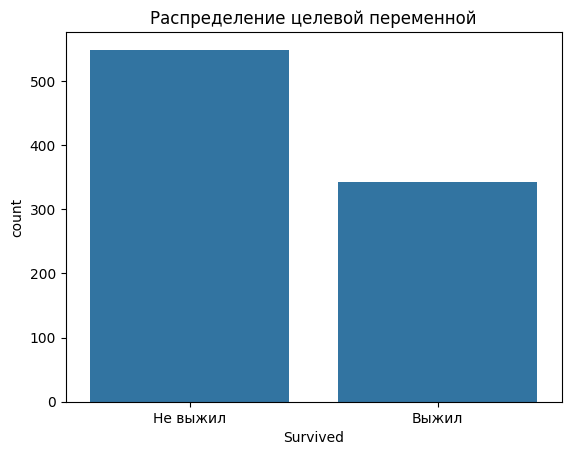

In [15]:
counts = df["Survived"].value_counts()
print(counts)
print((df["Survived"].value_counts(normalize=True) * 100).round(1))
ax = sns.countplot(data=df, x="Survived")
ax.set_xticks(ticks=[0, 1], labels=["Не выжил", "Выжил"])
ax.set_title("Распределение целевой переменной")
plt.show()

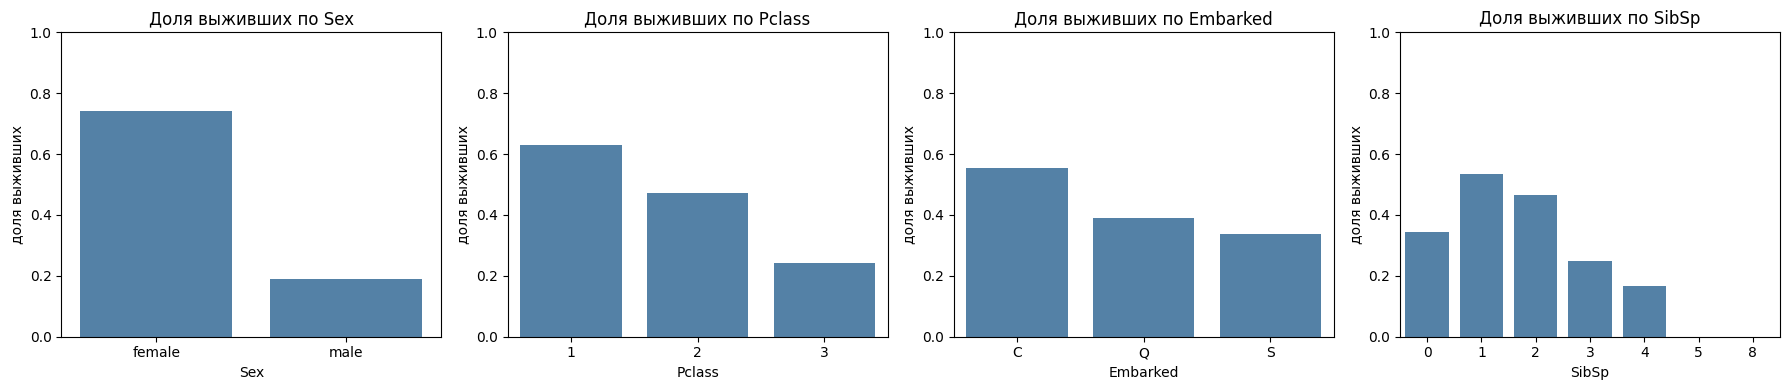

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


In [19]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked", "SibSp"]):
    rate = df.groupby(col)["Survived"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="steelblue")
    ax.set_title(f"Доля выживших по {col}")
    ax.set_ylim(0, 1)
    ax.set_ylabel("доля выживших")
plt.tight_layout()
plt.show()

display(df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean").round(2))

**Вывод**: среди выживших имеется некоторый перевес в сторону женщин, что согласуется с правилом "уступать место в спасательных шлюпках женщинам и детям". Также видно, что на выживаемость влиял и класс пассажирского билета. Это значит, что на предсказание влияет сочетания признаков, что хорошо для ядерных методов и деревьев решений.

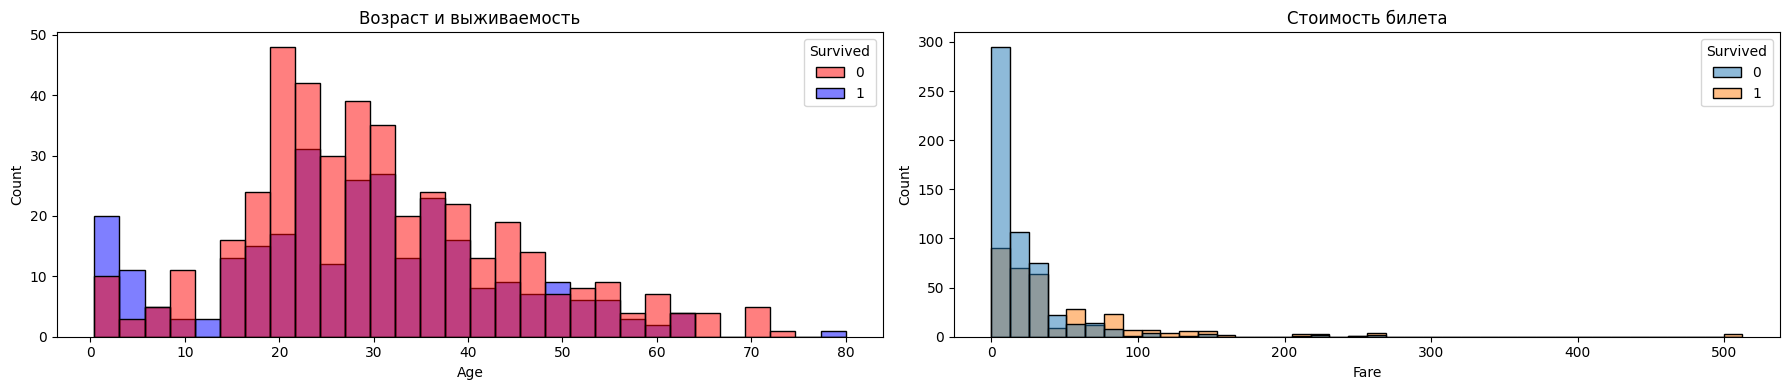

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(18, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=False, ax=axes[0], multiple="layer", palette={0: "red", 1: "blue"})
axes[0].set_title("Возраст и выживаемость")
sns.histplot(data=df, x="Fare", hue="Survived", bins=40, ax=axes[1], multiple="layer")
axes[1].set_title("Стоимость билета")
plt.tight_layout()
plt.show()

Как видно обе гистограммы `Fare` и `Age` имеют выраженный правый хвост, что отражает, что выживаемость среди людей, купивших более дорогие билеты и не являющиеся членами экипажа (их билет бесплатный), была выше. Правый хвост как минимум по этим признакам означает, что данные необходимо стандартизировать, так как модели SVM и KNN чувствительны к масштабу данных